# INFO 2950 Project: Phase 4

Troy Goetz (tmg85) and Nicholas Grabowski (nrg39)

**Chess openings and player ratings**

## Introduction

Chess players often decide which openings to learn by looking at how well those openings score in online databases. An opening that scores well among beginners might not work as well among stronger players. But a high average can also be misleading: perhaps the players using that opening usually faced weaker opponents.

**Our question:** Do some chess opening families perform better at different ratings, even after accounting for the rating gap between opponents?

**Chess terms used in this report**

- **White and Black.** The two sides. White moves first.
- **Opening.** The first several moves of a game. Named openings are well-studied move sequences, such as the Sicilian Defense (1.e4 c5).
- **Opening family.** A group of related openings under one name. Chess.com labels each game with a detailed variation, such as "Sicilian Defense: Alapin Variation"; we group variations into families such as "Sicilian."
- **Rating.** A number estimating a player's strength from their results; higher means stronger. Chess.com uses the Glicko system, so a 1500 player is expected to beat a 1300 player more often than not (Chess.com, n.d.-b). Most active Chess.com blitz players in our data are rated below 1000.
- **Rating gap.** White's rating minus Black's rating. A gap of +200 means White was rated 200 points higher.
- **Blitz.** Fast games in which each player has 3 to 5 minutes in total, sometimes with a 2-second bonus per move.

We measure performance from White's side: a win earns 1 point, a draw 0.5 and a loss 0. An average **White score** of 0.60 means White earned 60% of the available points. It is not necessarily a 60% win rate. A low White score in Sicilian games means Black scored well in those games.

**Why this matters.** Opening books, courses and database statistics are often recommended by rating level, and many players spend much of their study time on openings. If a raw win rate mostly reflects who an opening's players happen to face, a player could choose what to study on misleading evidence. De Marzo and Servedio (2023) found that players' opening repertoires and estimated opening complexity differ with rating in Lichess data. That gives us a reason to look for rating-related patterns, but it does not tell us which opening should score better in our Chess.com sample.

**Summary of findings.** We first carry out the two comparisons approved in Phase 2. Neither provides clear evidence of a difference, and both conclusions hold when we remove the one highly influential game, use all eligible games, or limit rating gaps. We then compare 13 families across three rating groups. Different openings have the highest estimated scores in each group, but no pairwise difference survives correction for multiple comparisons, and our main test finds no clear evidence that opening differences change with rating. Our data do not support a dependable recommendation for the best opening at each rating.

The revisions made in response to Phase 3 peer and TA feedback are listed in the section **Response to Phase 3 feedback** near the end of the report.

## Data description and cleaning

### Where the records came from

We collected Chess.com records through its public API (Chess.com, n.d.-a). We shuffled the public list of recently active US-listed accounts with seed 2950 and selected 300 accounts. We downloaded their available July-September 2026 monthly archives; the Phase 2 log records 900 successful requests. Their opponents could be from any country. Country is self-reported and does not establish residency.

Chess.com operates the platform and creates the game records as part of that service. Its staff and infrastructure make those records available through the Published Data API. We depend on what Chess.com records, preserves and chooses to expose (Chess.com, n.d.-a). We credit Chess.com as the data producer and provider.

**Why this dataset was created.** The underlying records exist so Chess.com can run its service: show players their game history, update ratings and support analysis. We assembled our version for this class project, to compare opening results across ratings. We used public information without contacting players, so we do not know whether they expected this classroom use. This description follows the motivation, composition and collection questions in Gebru et al. (2018).

### What shaped which games we observed

Several processes decided which games appear in our data and which do not:

1. **Who we sampled.** Only accounts on Chess.com's public list of recently active players with the United States as their country could be selected. Inactive players, players who list another country, and players who play mainly on other sites or over the board are absent as sampled accounts.
2. **How much each account plays.** We kept every blitz game from each selected account. An account that plays hundreds of games a month contributes far more rows than an occasional player, so heavy players shape the data much more than their share of accounts.
3. **The rating mix of active players.** Most randomly selected accounts were rated below 1000, so higher-rated games are scarce. In the 1500-1999 group, two source accounts supply 1,470 of 1,584 games.
4. **Chess.com's own choices.** Chess.com assigns the opening label, computes ratings, and decides which games and accounts remain public. For example, if an account was closed (for instance for fair-play reasons) before our download, its games may no longer appear. We cannot observe games that were removed before collection.
5. **Our filters.** We kept only rated, standard-rules blitz games from July-September 2026. Bullet, rapid, daily, unrated and variant games were recorded by Chess.com but excluded by us.

### What one row means

One row is a unique rated standard blitz game. White's rating is the recorded blitz rating at the time of the game. Chess.com uses Glicko, which includes uncertainty about ratings; our analysis does not fully observe that uncertainty (Chess.com, n.d.-b). Our four groups are Under 1000, 1000-1499, 1500-1999 and 2000+. These are comparison groups, not official skill titles.

| Columns | Meaning |
|---|---|
| `game_url`, `white_username`, `black_username` | Game identifier and the accounts playing each side. |
| `sampled_player`, `archive_month` | Source archive account and collection month; the source can be either player. |
| `white_rating`, `black_rating` | Recorded blitz ratings at the time of the game. |
| `white_result`, `black_result` | Platform result codes, including reasons such as resignation or timeout. |
| `rated`, `rules`, `time_class` | Eligibility fields: retained games are rated, standard chess and blitz. |
| `time_control` | Starting seconds and increment; `180+2` means three minutes plus two seconds per move. |
| `time_control_group` | Time control used as a model control: 180, 180+2 or 300 (the 10 five-minute games with an increment are grouped with 300). |
| `end_time` | Game-ending Unix timestamp, not duration. |
| `opening_url`, `pgn` | Chess.com's opening label/link and notation containing headers and moves. |
| `rating_group`, `rating_difference` | Group from White's rating; White's rating minus Black's rating. |
| `opening_family`, `game_result`, `white_score` | Joined family, completed PGN outcome and White score of 0, 0.5 or 1. |
| `gap100`, `sicilian`, `kings_pawn`, `rating_1000_1499` | Gap divided by 100 and binary model indicators, prepared in the cleaning notebook. |

The long `pgn` field remains in the raw and unaugmented prepared files; the model-ready CSVs omit that text because none of these analyses requires the moves. All modeled values are retained.

### Cleaning summary and source access

The raw download contains 64,738 rows. We keep rated standard blitz games, require nonblank URLs, remove duplicate URLs, convert ratings to numbers and require positive ratings for both players. We join one family per opening URL, read completed results from the PGN header and calculate White's score. These checks leave 29,385 games. Some checks remove zero rows; the companion notebook still records them in its audit table.

The documented lookup groups related variations under one family. The label describes the opening reached by both players, not a strategy White can freely choose alone. It is a classification of the source, not an independent dataset. Unknown labels stay in the prepared data and are excluded only when a named family is required.

**Two cleaning fixes since Phase 3.** While revising, we found that 14 families appeared twice, under a shortened name and a full name; for example, 40 games were labeled `Scotch` and 378 `Scotch Game`. The shortened labels all came from opening URLs whose variation starts with Black's move, which our original label rule cut too early. The cleaning notebook now checks that each affected URL begins with the full family name and merges the labels. This relabels 149 games and changes no game's inclusion. It does not affect the four families in our preregistered tests within the original sample, but it changes the broader comparison slightly (for example, Indian Game gains 21 games). Second, 10 five-minute games used an increment (300+2 or 300+5). In a model subset, a time control with a single game is fitted exactly, which made the Phase 3 HC3 calculation unstable. We group these 10 games with the other five-minute games.

The original sample contains 150 games per group, selected with seed 2950. We preserve its 600 game IDs for the preregistered tests. The larger-data analyses use eligible games from the full prepared set. The cleaning notebook verifies that regenerating the sample reproduces the archived game IDs, ratings, groups and outcomes.

Detailed cleaning is in the [separate cleaning notebook](https://github.com/Toyman123/info2950-project/blob/main/phase4/Chess_Data_Cleaning.ipynb), which exports the CSVs imported below. It is also included in the project folder as **Chess_Data_Cleaning.ipynb**. The notebook reads the fixed archive directly when opened in Colab, so reviewers do not need a local copy of the raw download.

Sources: [raw archive](https://github.com/Toyman123/info2950-project/blob/main/phase2/data/raw/chess_games_raw.csv.gz), [collection records](https://github.com/Toyman123/info2950-project/tree/main/phase2/data/raw), and [opening lookup](https://github.com/Toyman123/info2950-project/blob/main/phase2/data/opening_lookup.csv). The decompressed archive's SHA256 matches the original manifest. Using a fixed archive prevents later API changes from changing these results.

In [1]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import statsmodels.api as sm
from patsy import dmatrices, build_design_matrices
from itertools import combinations
from statsmodels.stats.multitest import multipletests
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb
from IPython.display import display, Markdown
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
rating_colors = ["#33658A", "#D17A22", "#3A8067", "#865D91"]
Path("figures").mkdir(exist_ok=True)
def p_text(p):
    return f"{p:.3g}" if p < .001 else f"{p:.3f}"
def title(text):
    display(Markdown(f"**{text}**"))
sample = pd.read_csv('data/chess_analysis_600_model_ready.csv')
full = pd.read_csv('data/chess_games_prepared_model_ready.csv')
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 110)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.float_format', '{:.4f}'.format)
print('Original sample:', len(sample), '| full prepared dataset:', len(full))

Original sample: 600 | full prepared dataset: 29385


### Opening coverage

We use SQL to count the games and Seaborn to show where we have enough data for comparisons (Waskom, 2021). The chart displays the eight most common named families, selected by game count rather than score. Each number is a game count, not a measure of how well the opening performed.

An opening label describes the position reached by both players. For example, White cannot choose a Sicilian game without Black's response. Throughout the report, "better performance" means a higher White score in games with that label; it does not mean White could freely choose the same opening in every game.

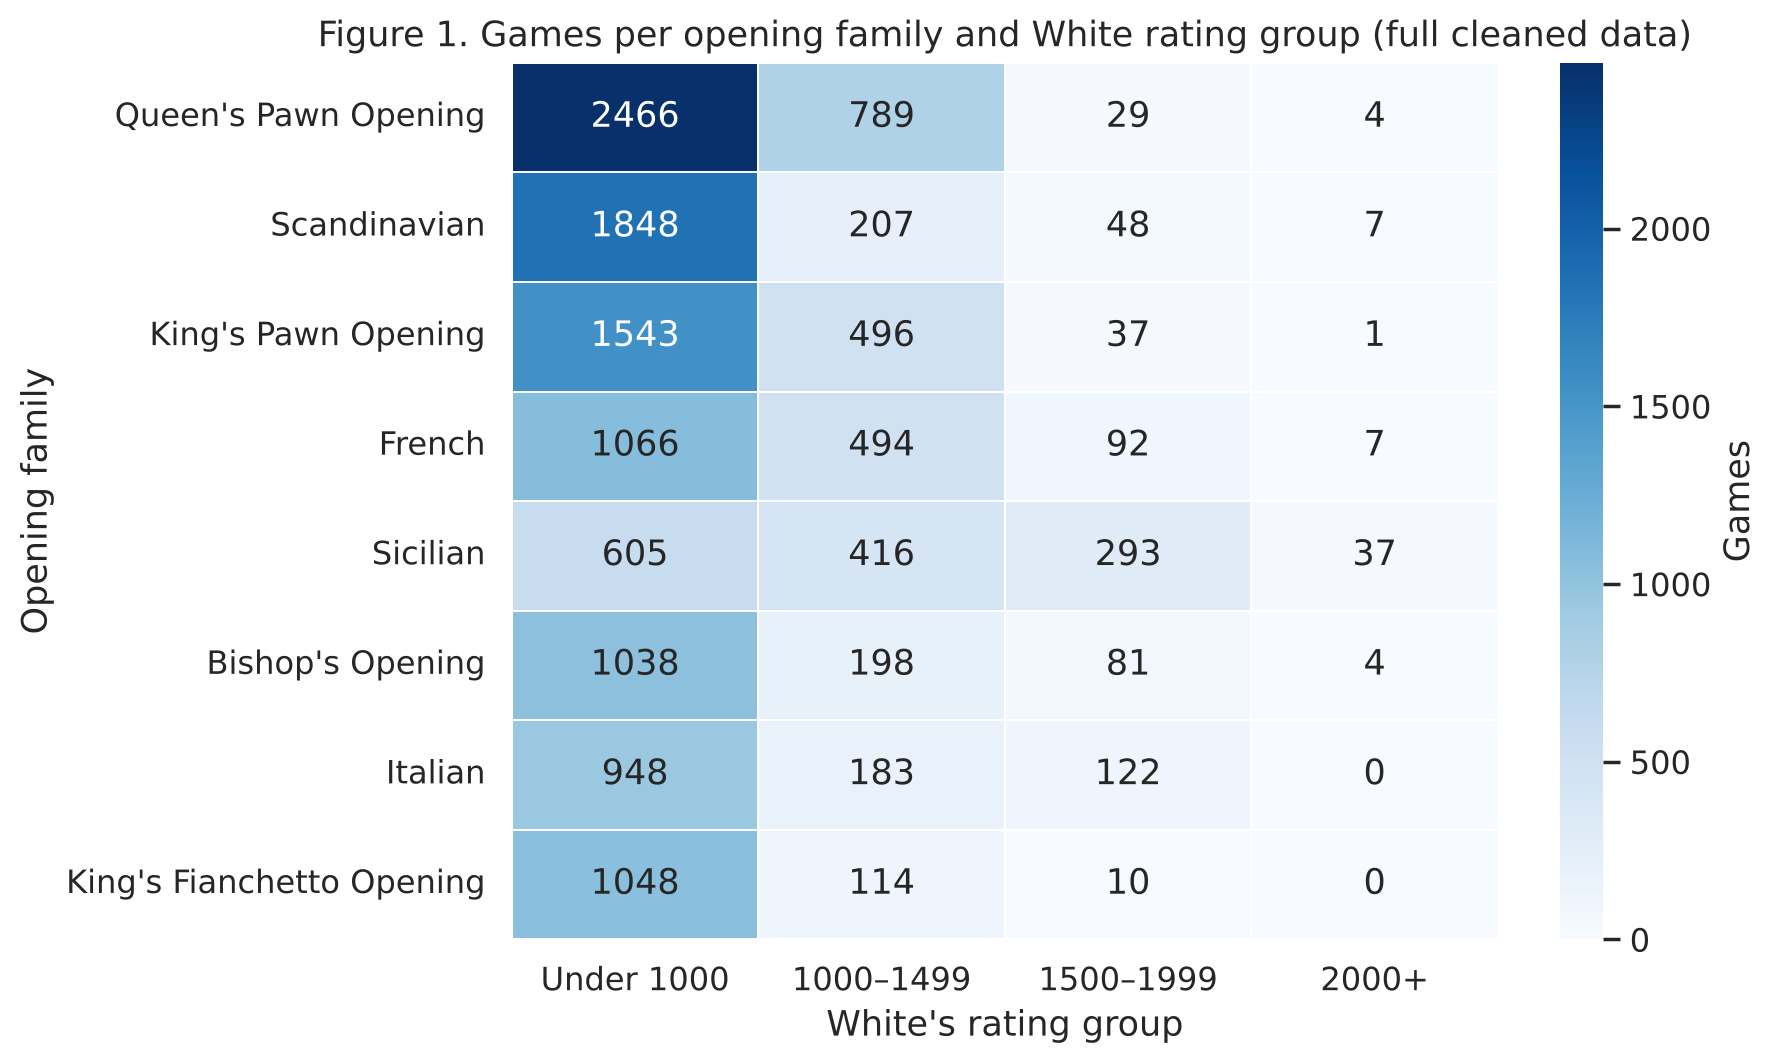

rating_group
Under 1000    20847
1000–1499      6771
1500–1999      1584
2000+           183


In [2]:
# SQL summarizes the clean full dataset; no new filtering/cleaning rules are added.
rating_order = ['Under 1000','1000–1499','1500–1999','2000+']
duckdb.register('clean_games', full)
coverage_sql = duckdb.sql('''
    WITH common AS (
        SELECT opening_family, COUNT(*) AS total_games
        FROM clean_games
        WHERE opening_family <> 'Unknown'
        GROUP BY opening_family
        ORDER BY total_games DESC, opening_family
        LIMIT 8
    )
    SELECT f.opening_family, f.rating_group,
           COUNT(*) AS games,
           COUNT(DISTINCT f.sampled_player) AS archive_accounts,
           AVG(f.white_score) AS mean_white_score,
           AVG(f.rating_difference) AS mean_rating_gap
    FROM clean_games AS f
    JOIN common AS c ON f.opening_family = c.opening_family
    GROUP BY f.opening_family, f.rating_group
    ORDER BY f.opening_family, f.rating_group
''').df()
family_order = (coverage_sql.groupby('opening_family')['games'].sum()
                .sort_values(ascending=False).index.tolist())
count_grid = (coverage_sql.pivot(index='opening_family', columns='rating_group', values='games')
              .reindex(index=family_order, columns=rating_order).fillna(0).astype(int))
fig, ax = plt.subplots(figsize=(9,5.5))
sns.heatmap(count_grid, annot=True, fmt='d', cmap='Blues', linewidths=.7, cbar_kws={'label':'Games'}, ax=ax)
ax.set(title='Figure 1. Games per opening family and White rating group (full cleaned data)',
       xlabel="White's rating group", ylabel='Opening family')
plt.tight_layout()
plt.show()
coverage_sql.to_csv('opening_rating_sql_summary.csv', index=False)
print(full.rating_group.value_counts().reindex(rating_order).to_string())

The data are uneven. The full set has 20,847 games under 1000, 6,771 at 1000-1499, 1,584 at 1500-1999 and 183 at 2000+. Most displayed families have fewer than ten games in the highest group.

Balancing the original sample at 150 games per group did not fix the small opening cells. The broader analysis later in the report therefore uses more games and limits its comparisons to families with coverage across the first three groups. We do not produce a broad ranking for 2000+.

## Preregistration statements

These are the two analyses we committed to in Phase 2, before fitting the models. We keep the original hypotheses, samples and decision rules. Later checks are labeled exploratory or sensitivity checks because we added them after Phase 2.

### 1. Sicilian versus French

**Hypothesis:** White's average score differs between Sicilian and French games after accounting for White's rating group and the opponents' rating gap.

**Real-world context.** The Sicilian (1.e4 c5) and French (1.e4 e6) are two of the most common replies to 1.e4, so a player who opens 1.e4 as White must prepare for both, and a player choosing a defense as Black often chooses between them. If one of them reliably gave White a lower score, that would be useful for deciding which defense to learn.

We planned to use the original 92 Sicilian and 34 French games. The linear regression predicts White's score from opening family, rating group and White-minus-Black rating gap divided by 100. French is the opening comparison group, and 1000-1499 is the rating comparison group.

We test whether the adjusted Sicilian-minus-French difference is zero. The test is two-sided: either opening could have the higher score. We use a 0.05 significance threshold and report the estimate and its 95% confidence interval regardless of the result. The original test treats games as independent observations, while recognizing that repeated players may make the uncertainty look smaller than it is.

This asks whether the opening difference remains after accounting for player strength. It estimates one average Sicilian-French difference across rating groups; it does not test whether that difference changes with rating.

### 2. Pawn openings below 1500

**Hypothesis:** The adjusted King's Pawn versus Queen's Pawn score difference changes between White's Under-1000 and 1000-1499 groups. We did not predict a direction.

**Real-world context.** Beginners are usually first taught either 1.e4 (King's Pawn) or 1.d4 (Queen's Pawn). Coaches often say open 1.e4 games suit beginners because they lead to quick tactics, while 1.d4 games reward slower planning as players improve. If that advice is right, the gap between the two should shift as players move from below 1000 to 1000-1499.

The original sample has 63 eligible games:

| Opening family | Under 1000 | 1000-1499 |
|---|---:|---:|
| King's Pawn Opening | 11 | 15 |
| Queen's Pawn Opening | 25 | 12 |

We chose these cells because each had at least ten games, not because of their scores. The regression includes opening, rating group, their interaction and rating gap divided by 100. Queen's Pawn and Under 1000 are the comparison categories.

The **interaction** measures how much the King's-minus-Queen's Pawn difference changes between the two groups. We test whether that change is zero using a two-sided test at 0.05, and report its estimate and 95% confidence interval. As planned, we use conventional independent-game uncertainty estimates and check residuals and predictions outside 0-1.

Both questions are motivated by possible differences in opening knowledge and choices across ratings (De Marzo & Servedio, 2023). Neither assumes that one opening must win. Chess.com's rating explanation also motivates controlling for the opponents' strength gap rather than comparing raw opening averages alone (Chess.com, n.d.-b).

## Data analysis

### How to read the results

Each estimate below is a difference in average White score. For example, a difference of 0.05 is five percentage points of the available game points, not necessarily five percentage points of win probability.

A **confidence interval** shows the uncertainty around an estimate under the model's assumptions. A wide interval means the estimate is imprecise. An interval that includes both negative and positive differences leaves room for either opening to score better.

A **p-value** measures how surprising a result at least this extreme would be under the specified no-difference model and its assumptions. For the two planned tests, p below 0.05 leads us to reject that no-difference hypothesis. A larger p-value means we fail to reject it; it does not prove the openings are equal.

A **rating-gap coefficient** describes the change in White's expected score for a 100-point increase in White's advantage over Black. Opening and rating comparisons hold the other predictors fixed.

In [3]:
# Subsetting here selects the preregistered populations; it does not reclean data.
def subsets(frame):
    a = frame[frame.opening_family.isin(['Sicilian', 'French'])].copy()
    b = frame[frame.opening_family.isin(["King's Pawn Opening", "Queen's Pawn Opening"]) & (frame.white_rating < 1500)].copy()
    return a, b
f1 = "white_score ~ sicilian + C(rating_group, Treatment(reference='1000–1499')) + gap100"
f2 = 'white_score ~ kings_pawn * rating_1000_1499 + gap100'
a1, a2 = subsets(sample)
assert len(a1) == 126 and len(a2) == 63
m1 = smf.ols(f1, data=a1).fit()
m2 = smf.ols(f2, data=a2).fit()
names = {'sicilian':'Sicilian minus French', 'gap100':'White–Black rating gap (+100 points)',
         'kings_pawn':"King's minus Queen's Pawn (under 1000)",
         'rating_1000_1499':"1000–1499 minus Under 1000 (Queen's Pawn)",
         'kings_pawn:rating_1000_1499':'Change in opening contrast between rating groups'}
def coefficient_table(model):
    ci = model.conf_int()
    table = pd.DataFrame({'estimate':model.params, '95% CI lower':ci[0], '95% CI upper':ci[1], 'p-value':model.pvalues})
    table.index = [names.get(term, 'White group '+term.split('[T.')[-1].rstrip(']')+' vs 1000–1499' if '[T.' in term else term) for term in table.index]
    table['p-value'] = table['p-value'].map(p_text)
    return table.round(4)
title('Table 1. Games in Analysis 1 (Sicilian vs French), original sample')
display(pd.crosstab(a1.opening_family, a1.rating_group).reindex(columns=rating_order))
title('Table 2. Games in Analysis 2 (pawn openings below 1500), original sample')
display(pd.crosstab(a2.opening_family, a2.rating_group).reindex(columns=rating_order[:2]))
title('Table 3. Analysis 1 regression: Sicilian vs French (126 games, conventional uncertainty)')
display(coefficient_table(m1))
title('Table 4. Analysis 2 regression: pawn-opening interaction (63 games, conventional uncertainty)')
display(coefficient_table(m2))

**Table 1. Games in Analysis 1 (Sicilian vs French), original sample**

rating_group,Under 1000,1000–1499,1500–1999,2000+
opening_family,,,,
French,6,14,7,7
Sicilian,4,15,41,32


**Table 2. Games in Analysis 2 (pawn openings below 1500), original sample**

rating_group,Under 1000,1000–1499
opening_family,,
King's Pawn Opening,11,15
Queen's Pawn Opening,25,12


**Table 3. Analysis 1 regression: Sicilian vs French (126 games, conventional uncertainty)**

,estimate,95% CI lower,95% CI upper,p-value
Intercept,0.4817,0.2744,0.6891,1.05e-05
White group 1500–1999 vs 1000–1499,-0.0151,-0.2505,0.2204,0.899
White group 2000+ vs 1000–1499,-0.0313,-0.2763,0.2137,0.801
White group Under 1000 vs 1000–1499,-0.0394,-0.3910,0.3121,0.825
Sicilian minus French,0.0117,-0.1952,0.2186,0.911
White–Black rating gap (+100 points),0.0962,0.0252,0.1672,0.008


**Table 4. Analysis 2 regression: pawn-opening interaction (63 games, conventional uncertainty)**

,estimate,95% CI lower,95% CI upper,p-value
Intercept,0.5140,0.3321,0.6960,4.98e-07
King's minus Queen's Pawn (under 1000),0.2146,-0.1185,0.5478,0.202
1000–1499 minus Under 1000 (Queen's Pawn),-0.1455,-0.4637,0.1727,0.364
Change in opening contrast between rating groups,-0.1306,-0.6158,0.3547,0.592
White–Black rating gap (+100 points),0.8122,0.4064,1.2181,0.000178


### What the original comparisons show

**1. Sicilian versus French:** the adjusted difference is 0.012 score points, with a 95% interval from -0.195 to 0.219 and p = 0.911. The point estimate is small, but the interval is wide: it allows the Sicilian to score up to about 0.2 lower or 0.2 higher than the French for White. This sample does not clearly favor either family. The rating-gap coefficient (0.096 per 100 points, p = 0.008) shows that opponent strength does matter: a 100-point rating advantage raises White's expected score by about 0.1.

**2. Pawn-opening interaction:** the estimated change between groups is -0.131, with a 95% interval from -0.616 to 0.355 and p = 0.592. We do not have clear evidence that the opening difference changes between the two rating groups. With only 63 games, the interval is too wide to rule out large changes in either direction.

The next table and chart show what the fitted models predict when White and Black have equal ratings. The intervals describe uncertainty in the average score, not the range of results for an individual game.

In [4]:
pred1 = pd.DataFrame({'sicilian':[0,1]*4, 'rating_group':np.repeat(rating_order,2), 'gap100':0})
pred2 = pd.DataFrame({'kings_pawn':[0,1,0,1], 'rating_1000_1499':[0,0,1,1], 'gap100':0})
for model, grid, kind, label in [(m1, pred1, 'sicilian', 'Table 5. Analysis 1 fitted White scores at equal ratings'),
                                 (m2, pred2, 'pawn', 'Table 6. Analysis 2 fitted White scores at equal ratings')]:
    output = model.get_prediction(grid).summary_frame()
    if kind == 'sicilian':
        labels = pd.DataFrame({'Opening':grid.sicilian.map({0:'French',1:'Sicilian'}), 'White rating group':grid.rating_group})
    else:
        labels = pd.DataFrame({'Opening':grid.kings_pawn.map({0:"Queen's Pawn",1:"King's Pawn"}),
                               'White rating group':grid.rating_1000_1499.map({0:'Under 1000',1:'1000–1499'})})
    labels['Expected White score'] = output['mean']
    labels['95% CI'] = [f'{a:.3f} to {b:.3f}' for a, b in zip(output.mean_ci_lower, output.mean_ci_upper)]
    title(label)
    display(labels.reset_index(drop=True))

**Table 5. Analysis 1 fitted White scores at equal ratings**

,Opening,White rating group,Expected White score,95% CI
0,French,Under 1000,0.4423,0.129 to 0.756
1,Sicilian,Under 1000,0.4540,0.127 to 0.781
2,French,1000–1499,0.4817,0.274 to 0.689
3,Sicilian,1000–1499,0.4935,0.290 to 0.697
4,French,1500–1999,0.4667,0.242 to 0.691
5,Sicilian,1500–1999,0.4784,0.337 to 0.620
6,French,2000+,0.4504,0.220 to 0.681
7,Sicilian,2000+,0.4622,0.302 to 0.622


**Table 6. Analysis 2 fitted White scores at equal ratings**

,Opening,White rating group,Expected White score,95% CI
0,Queen's Pawn,Under 1000,0.5140,0.332 to 0.696
1,King's Pawn,Under 1000,0.7287,0.455 to 1.002
2,Queen's Pawn,1000–1499,0.3685,0.110 to 0.627
3,King's Pawn,1000–1499,0.4526,0.222 to 0.684


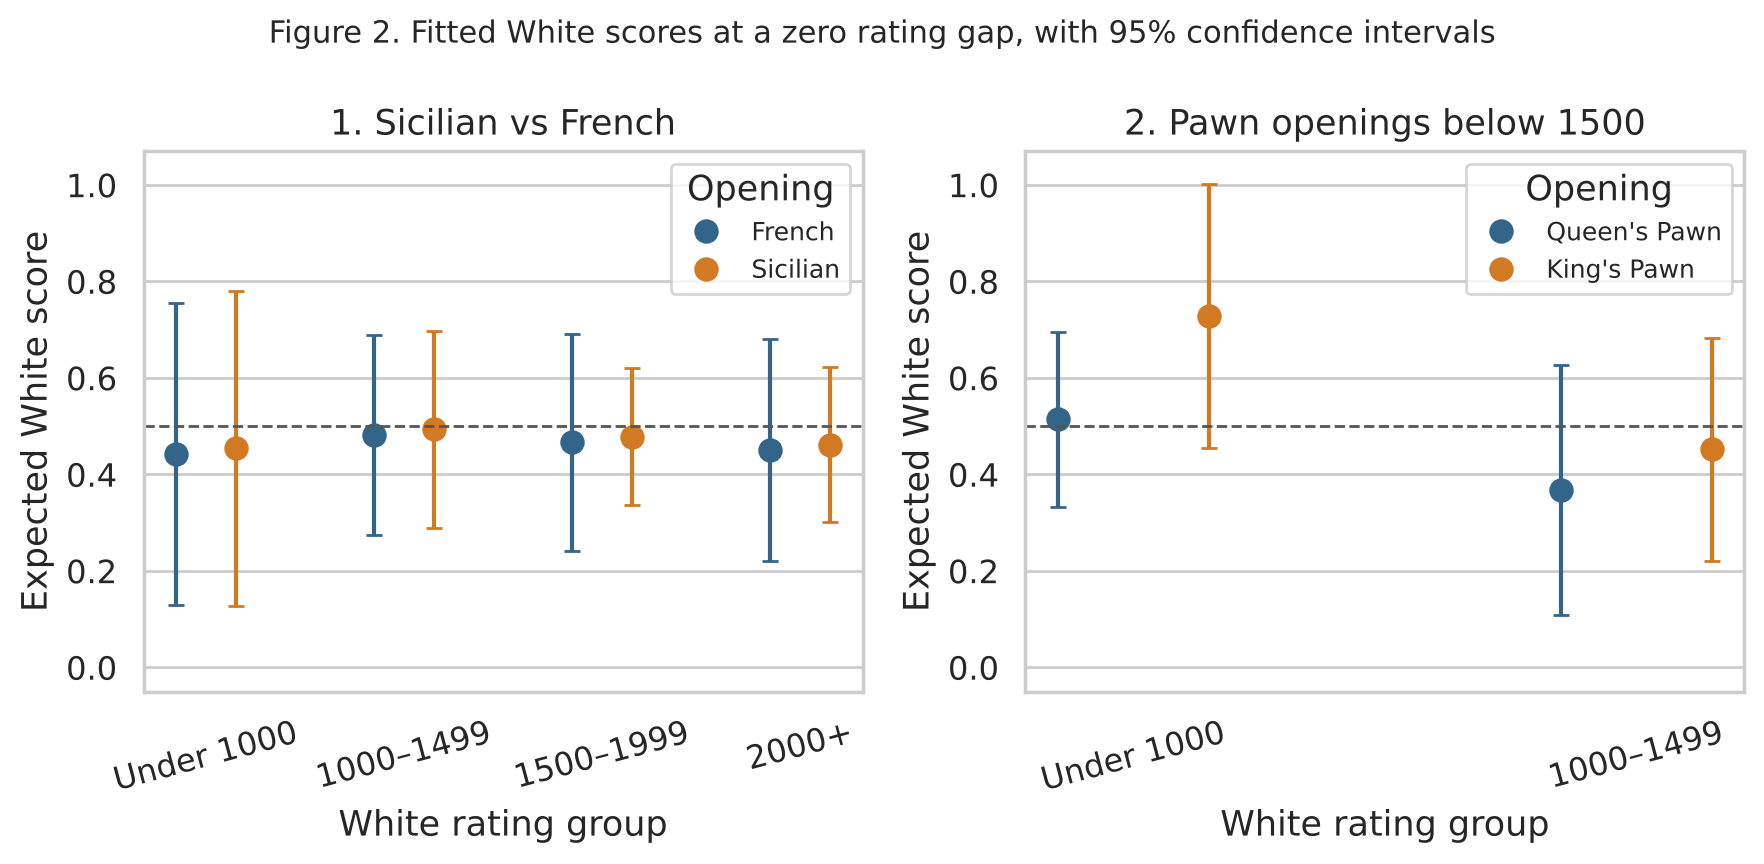

In [5]:
# Seaborn lays out adjusted means; Matplotlib adds the computed OLS intervals.
fig, axes = plt.subplots(1, 2, figsize=(9, 4.4))
for ax, model, grid, indicator, panel in [
    (axes[0], m1, pred1, 'sicilian', '1. Sicilian vs French'),
    (axes[1], m2, pred2, 'kings_pawn', '2. Pawn openings below 1500')]:
    predicted = grid.copy()
    intervals = model.get_prediction(grid).summary_frame()
    predicted['Expected White score'] = intervals['mean']
    predicted['Lower'] = intervals['mean_ci_lower']
    predicted['Upper'] = intervals['mean_ci_upper']
    if indicator == 'sicilian':
        predicted['White rating group'] = predicted.rating_group
        predicted['Opening'] = predicted.sicilian.map({0:'French',1:'Sicilian'})
        order, hue_order = rating_order, ['French','Sicilian']
    else:
        predicted['White rating group'] = predicted.rating_1000_1499.map({0:'Under 1000',1:'1000–1499'})
        predicted['Opening'] = predicted.kings_pawn.map({0:"Queen's Pawn",1:"King's Pawn"})
        order, hue_order = rating_order[:2], ["Queen's Pawn","King's Pawn"]
    palette = dict(zip(hue_order, ['#33658A','#D17A22']))
    sns.pointplot(data=predicted, x='White rating group', y='Expected White score', hue='Opening', order=order,
                  hue_order=hue_order, palette=palette, dodge=.3, errorbar=None, linestyles='none', ax=ax)
    for _, row in predicted.iterrows():
        x = order.index(row['White rating group']) + (-.15 if row['Opening'] == hue_order[0] else .15)
        ax.errorbar(x, row['Expected White score'], yerr=[[row['Expected White score']-row.Lower],[row.Upper-row['Expected White score']]],
                    fmt='none', ecolor=palette[row.Opening], capsize=3)
    ax.axhline(.5, color='#555555', linestyle='--', linewidth=1)
    ax.set_title(panel)
    ax.tick_params(axis='x', rotation=15)
    ax.set_ylim(-.05, 1.07)
    ax.legend(title='Opening', fontsize=9)
fig.suptitle('Figure 2. Fitted White scores at a zero rating gap, with 95% confidence intervals', fontsize=11)
plt.tight_layout()
plt.show()

In the Sicilian-French model, the 1000-1499 group has fitted scores of about 0.48 for French and 0.49 for Sicilian. That model assumes the same opening difference across rating groups, which explains the roughly parallel pairs of points.

The pawn-opening model allows the difference to change. Under 1000, it predicts about 0.73 for King's Pawn and 0.51 for Queen's Pawn, a gap of about 0.215. At 1000-1499, the predictions are about 0.45 and 0.37, a gap of about 0.084. Subtracting the two gaps gives the interaction of about -0.131.

Those fitted differences look interesting, but their uncertainty is large. The interaction test, rather than the appearance of the points alone, is our planned test of whether the gap changes.

### Checking unusual games and model fit

We compare each game's actual score with its fitted score. Their difference is the **residual**. The plots help us see unusual games and patterns the model may have missed.

A linear model can produce fitted scores outside 0-1, even though a game's actual score cannot fall outside that range. We check for this problem and for games that have an unusually strong influence on the fit. **Cook's distance** measures how much all the fitted values would change if one game were removed; values far above 1 flag a game that by itself moves the results. **R-squared** is the share of variation in recorded scores accounted for by the fitted model. It does not measure whether an opening causes a better result or how accurately the model would predict new games. An unusual result is not evidence of cheating.

**Table 7. Fit and influence diagnostics for the two planned models**

,model,n,R-squared,fitted min,fitted max,fitted outside 0–1,max Cook distance,source accounts,largest source account share
0,1. Sicilian–French,126,0.0576,0.3198,1.6854,1,15.2128,18,0.3651
1,2. Pawn interaction,63,0.2521,-0.0510,0.9851,1,0.1557,27,0.2063


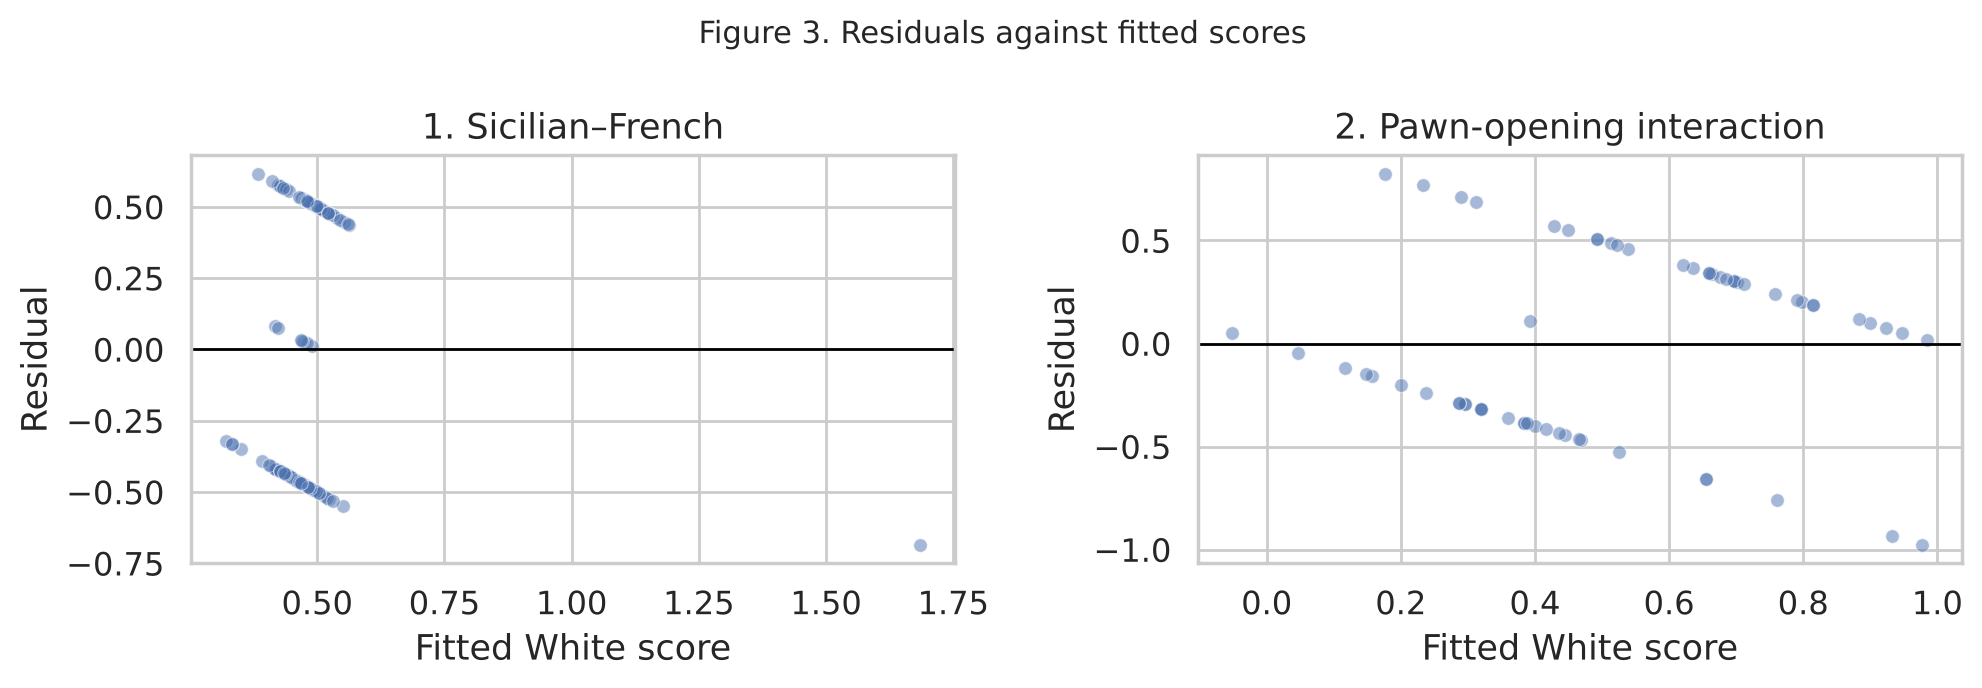

In [6]:
diagnostics = []
for label, model, frame in [('1. Sicilian–French', m1, a1), ('2. Pawn interaction', m2, a2)]:
    influence = model.get_influence()
    diagnostics.append({'model':label, 'n':len(frame), 'R-squared':model.rsquared,
                        'fitted min':model.fittedvalues.min(), 'fitted max':model.fittedvalues.max(),
                        'fitted outside 0–1':int(((model.fittedvalues < 0) | (model.fittedvalues > 1)).sum()),
                        'max Cook distance':float(np.max(influence.cooks_distance[0])),
                        'source accounts':frame.sampled_player.nunique(),
                        'largest source account share':frame.sampled_player.value_counts(normalize=True).max()})
title('Table 7. Fit and influence diagnostics for the two planned models')
display(pd.DataFrame(diagnostics).round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, model, panel in zip(axes, [m1, m2], ['1. Sicilian–French', '2. Pawn-opening interaction']):
    sns.scatterplot(x=model.fittedvalues, y=model.resid, alpha=.5, s=24, ax=ax)
    ax.axhline(0, color='black', linewidth=1)
    ax.set(xlabel='Fitted White score', ylabel='Residual', title=panel)
fig.suptitle('Figure 3. Residuals against fitted scores', fontsize=11)
fig.tight_layout()
plt.show()

The first model has one fitted score above 1, at about 1.69, and its largest Cook's distance is 15.21, far above every other game (the next largest is 0.03). The second model has one fitted score slightly below zero, and no game has a large Cook's distance. The bands in the residual plots come from the three possible actual scores: 0, 0.5 and 1.

### Does one game drive Analysis 1?

Following the TA's suggestion, we identify the influential game and refit the planned Sicilian-French model without it. We keep the game in the preregistered test above, because our Phase 2 plan had no rule for removing games; this refit is a sensitivity check.

In [7]:
cooks = m1.get_influence().cooks_distance[0]
position = int(np.argmax(cooks))
influential = a1.iloc[[position]][['opening_family','rating_group','white_rating','black_rating','rating_difference','white_score','time_control']]
influential['fitted score'] = m1.fittedvalues.iloc[position]
influential["Cook's distance"] = cooks[position]
title("Table 8. The game with the largest Cook's distance in Analysis 1")
display(influential.reset_index(drop=True))
m1_drop = smf.ols(f1, data=a1.drop(a1.index[position])).fit()
compare = []
for label, model in [('With the game (planned test)', m1), ('Without the game', m1_drop)]:
    ci = model.conf_int()
    for term in ['sicilian', 'gap100']:
        compare.append({'Model':label, 'Term':names[term], 'Games':int(model.nobs), 'Estimate':model.params[term],
                        'Lower':ci.loc[term, 0], 'Upper':ci.loc[term, 1], 'p-value':p_text(model.pvalues[term])})
title('Table 9. Analysis 1 with and without the influential game')
display(pd.DataFrame(compare).round(3))
print('Largest Cook distance after removal:', round(float(np.max(m1_drop.get_influence().cooks_distance[0])), 3))

**Table 8. The game with the largest Cook's distance in Analysis 1**

,opening_family,rating_group,white_rating,black_rating,rating_difference,white_score,time_control,fitted score,Cook's distance
0,Sicilian,2000+,2318,1046,1272,1.0000,180,1.6854,15.2128


**Table 9. Analysis 1 with and without the influential game**

,Model,Term,Games,Estimate,Lower,Upper,p-value
0,With the game (planned test),Sicilian minus French,126,0.0120,-0.1950,0.2190,0.911
1,With the game (planned test),White–Black rating gap (+100 points),126,0.0960,0.0250,0.1670,0.008
2,Without the game,Sicilian minus French,125,0.0550,-0.1410,0.2510,0.578
3,Without the game,White–Black rating gap (+100 points),125,0.4330,0.2560,0.6110,4.02e-06


Largest Cook distance after removal: 0.04


The influential game is a 2000+ Sicilian game in which White (rated 2318) beat a Black player rated 1046, a 1,272-point gap. No other game in the 126-game sample comes close to this gap, so the straight-line model extended its rating-gap slope far beyond the rest of the data and predicted an impossible score of 1.69.

Removing it moves the Sicilian-minus-French estimate from 0.012 to 0.055 (95% interval -0.141 to 0.251, p = 0.578). The conclusion does not change: there is still no clear evidence that the two families differ. The game mattered much more for the rating-gap slope, which rises from 0.096 to 0.433 per 100 points once that extreme gap no longer flattens the line. After removal, no game has a Cook's distance above 0.04. Because this extreme game was also the only one with a gap above 400 points, the "gap at most 400" check below is the same refit.

### Checking the original results with more data

Following the TA's Phase 2 feedback, we repeat the two opening comparisons using all eligible games from the full cleaned set and account for time control (3 minutes, 3 minutes plus 2 seconds, or 5 minutes), since faster games may favor different openings. We also repeat them using only games where the players are no more than 400 rating points apart. The 400-point cutoff is an extra check chosen after Phase 2, not an original exclusion rule or a claim that larger gaps are errors.

For the full-data checks we use **HC3 standard errors**. Ordinary regression intervals assume every game's result is equally unpredictable. HC3 relaxes that assumption, so games in some groups can have more variable results than others. It still assumes separate games are independent, so it does not solve the repeated-player problem (statsmodels developers, n.d.).

The companion `analysis_results.csv` records all twelve fitted versions.

In [8]:
rows = []
def record(label, model, term):
    ci = model.conf_int().loc[term]
    rows.append({'analysis':label, 'n':int(model.nobs), 'estimate':model.params[term],
                 'CI lower':ci.iloc[0], 'CI upper':ci.iloc[1], 'p-value':model.pvalues[term]})
for num, formula, term in [(1, f1, 'sicilian'), (2, f2, 'kings_pawn:rating_1000_1499')]:
    small = subsets(sample)[num-1]
    large = subsets(full)[num-1]
    tc = formula + ' + C(time_control_group)'
    record(f'{num}: original OLS', smf.ols(formula, data=small).fit(), term)
    record(f'{num}: original |gap| <= 400 OLS', smf.ols(formula, data=small[small.rating_difference.abs() <= 400]).fit(), term)
    record(f'{num}: original HC3', smf.ols(formula, data=small).fit(cov_type='HC3'), term)
    record(f'{num}: full OLS', smf.ols(formula, data=large).fit(), term)
    record(f'{num}: full + time control HC3', smf.ols(tc, data=large).fit(cov_type='HC3'), term)
    record(f'{num}: full + time, |gap| <= 400 HC3', smf.ols(tc, data=large[large.rating_difference.abs() <= 400]).fit(cov_type='HC3'), term)
results = pd.DataFrame(rows)
results.to_csv('analysis_results.csv', index=False)
labels = {'1: original OLS':'1. Sicilian–French: planned sample',
          '1: original |gap| <= 400 OLS':'1. Sicilian–French: planned sample, gaps ≤ 400 (= without influential game)',
          '1: full + time control HC3':'1. Sicilian–French: full data + time control',
          '1: full + time, |gap| <= 400 HC3':'1. Sicilian–French: full data + time, gaps ≤ 400',
          '2: original OLS':'2. Pawn interaction: planned sample',
          '2: full + time control HC3':'2. Pawn interaction: full data + time control',
          '2: full + time, |gap| <= 400 HC3':'2. Pawn interaction: full data + time, gaps ≤ 400'}
shown = results[results.analysis.isin(labels)].copy()
shown['analysis'] = shown.analysis.map(labels)
shown['p-value'] = shown['p-value'].map(p_text)
shown = shown.rename(columns={'analysis':'Analysis/check', 'n':'Games', 'estimate':'Estimate', 'CI lower':'Lower', 'CI upper':'Upper'})
title('Table 10. The two planned comparisons under the original and larger-data checks (95% intervals)')
display(shown.round(3).reset_index(drop=True))

**Table 10. The two planned comparisons under the original and larger-data checks (95% intervals)**

,Analysis/check,Games,Estimate,Lower,Upper,p-value
0,1. Sicilian–French: planned sample,126,0.0120,-0.1950,0.2190,0.911
1,"1. Sicilian–French: planned sample, gaps ≤ 400 (= without influential game)",125,0.0550,-0.1410,0.2510,0.578
2,1. Sicilian–French: full data + time control,3010,0.0110,-0.0240,0.0470,0.531
3,"1. Sicilian–French: full data + time, gaps ≤ 400",3003,0.0220,-0.0100,0.0530,0.178
4,2. Pawn interaction: planned sample,63,-0.1310,-0.6160,0.3550,0.592
5,2. Pawn interaction: full data + time control,5294,0.0260,-0.0280,0.0800,0.343
6,"2. Pawn interaction: full data + time, gaps ≤ 400",5288,0.0290,-0.0240,0.0820,0.286


Using all eligible games narrows the intervals a great deal. For Sicilian versus French, the interval shrinks from about ±0.2 to about -0.02 to 0.05 (3,010 games); for the pawn interaction, from about ±0.5 to about -0.03 to 0.08 (over 5,000 games). Every version still includes zero, and none is significant at 0.05. With far more data, the estimated differences are also small: a few hundredths of a point. So the larger data do not just fail to find a difference; they suggest any difference in these comparisons is likely small.

### Broader comparison: does the opening difference change with rating?

The two original tests cover only a few families. To address our broader question, we compare every family with at least 30 games in each of Under 1000, 1000-1499 and 1500-1999. Thirteen families qualify. This is an **exploratory analysis**: we added the coverage rule after Phase 2 and had already seen some descriptive results. Thirty games is a practical coverage rule, not a guarantee of a reliable estimate.

The model uses opening family, rating group, the opening-by-rating interactions, rating gap and time control. An interaction allows an opening difference to change with rating. For example, French could score below Sicilian in one group but above it in another. The **joint interaction test** checks all the opening-by-rating differences together, rather than choosing one after looking at the results. There are 24 interaction coefficients in this model.

**HC3 is our main uncertainty method.** In Phase 3 we also reported **source-account clustering**, which treats games from the same sampled account as related. The two methods gave very different answers, and we asked reviewers which to trust. Clustering is only reliable when there are many clusters in every part of the comparison (Cameron & Miller, 2015). Our 1500-1999 group has only five source accounts, so the clustered uncertainty is itself very imprecise and tends to be too small, which can make results look far more significant than they are. Following the TA's advice, we use HC3 as the main result and report clustering only as a flagged, unstable check.

To address the repeated-player concern in a more transparent way, the TA suggested aggregating so each account counts once. We average each source account's games within each opening family and rating group, so an account that played 500 Sicilian games contributes one row for that cell, the same as an account that played one. We then rerun the joint test on these account-level averages. We also check whether the joint result changes when we restrict rating gaps to 400 points or allow a curved (quadratic) relationship between rating gap and score.

In [9]:
all_counts = pd.crosstab(full.opening_family, full.rating_group)
groups = rating_order[:3]
eligible = all_counts.index[(all_counts[groups] >= 30).all(axis=1)].tolist()
explore = full[full.opening_family.isin(eligible) & full.rating_group.isin(groups)].copy()
formula = ("white_score ~ C(opening_family, Treatment(reference='Italian')) * "
           "C(rating_group, Treatment(reference='Under 1000')) + gap100 + C(time_control_group)")
y, X = dmatrices(formula, explore, return_type='dataframe')
design_info = X.design_info
extended = sm.OLS(y, X).fit()
hc3 = extended.get_robustcov_results(cov_type='HC3', use_t=True)
clustered = extended.get_robustcov_results(cov_type='cluster', groups=explore.sampled_player,
                                           use_correction=True, df_correction=True, use_t=True)
def joint_p(model, columns):
    ids = [i for i, name in enumerate(columns) if ':' in name]
    return float(model.wald_test(np.eye(len(columns))[ids], scalar=True).pvalue), len(ids)
assert np.linalg.matrix_rank(X) == X.shape[1]
print('Exploratory games:', len(explore), '| families:', len(eligible), '| largest leverage:', round(extended.get_influence().hat_matrix_diag.max(), 3))
title('Table 11. Games and source accounts in the exploratory comparison')
display(explore.groupby('rating_group').agg(Games=('game_url','size'), Source_accounts=('sampled_player','nunique')).reindex(groups))

# Account-level version: one row per source account, opening family and rating group.
account = explore.assign(tc_300=(explore.time_control_group == '300').astype(float),
                         tc_180_2=(explore.time_control_group == '180+2').astype(float))
account = (account.groupby(['sampled_player','opening_family','rating_group'])
           .agg(white_score=('white_score','mean'), gap100=('gap100','mean'), tc_300=('tc_300','mean'),
                tc_180_2=('tc_180_2','mean'), games=('white_score','size')).reset_index())
account_formula = formula.replace('C(time_control_group)', 'tc_300 + tc_180_2')
ya, Xa = dmatrices(account_formula, account, return_type='dataframe')
account_fit = sm.OLS(ya, Xa).fit(cov_type='HC3', use_t=True)

checks = []
p, k = joint_p(hc3, X.columns)
checks.append({'Joint test of 24 interaction terms':'All eligible games, HC3', 'Role':'Main result', 'Rows':len(explore), 'Joint p-value':p})
for label, frame, extra in [('Absolute gap at most 400, HC3', explore[explore.rating_difference.abs() <= 400], ''),
                            ('Quadratic rating-gap term, HC3', explore, ' + I(gap100 ** 2)')]:
    yy, xx = dmatrices(formula + extra, frame, return_type='dataframe')
    fitted = sm.OLS(yy, xx).fit(cov_type='HC3', use_t=True)
    checks.append({'Joint test of 24 interaction terms':label, 'Role':'Sensitivity check', 'Rows':len(frame), 'Joint p-value':joint_p(fitted, xx.columns)[0]})
checks.append({'Joint test of 24 interaction terms':'One row per account × opening × rating group, HC3', 'Role':'Sensitivity check (TA suggestion)',
               'Rows':len(account), 'Joint p-value':joint_p(account_fit, Xa.columns)[0]})
checks.append({'Joint test of 24 interaction terms':'All eligible games, source-account clustered', 'Role':'Flagged unstable (5 accounts in 1500–1999)',
               'Rows':len(explore), 'Joint p-value':joint_p(clustered, X.columns)[0]})
checks = pd.DataFrame(checks)
title('Table 12. Does the opening difference change with rating? Main test and checks')
display(checks.assign(**{'Joint p-value':checks['Joint p-value'].map(p_text)}))
title('Table 13. Rows in the account-level version')
display(account.groupby('rating_group').agg(Rows=('games','size'), Source_accounts=('sampled_player','nunique')).reindex(groups))

Exploratory games: 14208 | families: 13 | largest leverage: 0.078


**Table 11. Games and source accounts in the exploratory comparison**

,Games,Source_accounts
rating_group,,
Under 1000,10175,110
1000–1499,2861,27
1500–1999,1172,5


**Table 12. Does the opening difference change with rating? Main test and checks**

,Joint test of 24 interaction terms,Role,Rows,Joint p-value
0,"All eligible games, HC3",Main result,14208,0.804
1,"Absolute gap at most 400, HC3",Sensitivity check,14181,0.047
2,"Quadratic rating-gap term, HC3",Sensitivity check,14208,0.719
3,"One row per account × opening × rating group, HC3",Sensitivity check (TA suggestion),891,0.724
4,"All eligible games, source-account clustered",Flagged unstable (5 accounts in 1500–1999),14208,2.28e-26


**Table 13. Rows in the account-level version**

,Rows,Source_accounts
rating_group,,
Under 1000,704,110
1000–1499,149,27
1500–1999,38,5


### Comparing adjusted opening scores

For the chart, we set White and Black to equal ratings and use the same mix of time controls for every opening and group. That gives the fitted scores a common basis for comparison.

Each point is an estimated average White score. Each horizontal line is its HC3 95% confidence interval. The dashed line at 0.50 marks an equal share of the available points for White and Black. It is not a test of which opening is best. The intervals apply to individual fitted means, not to all opening comparisons at once.

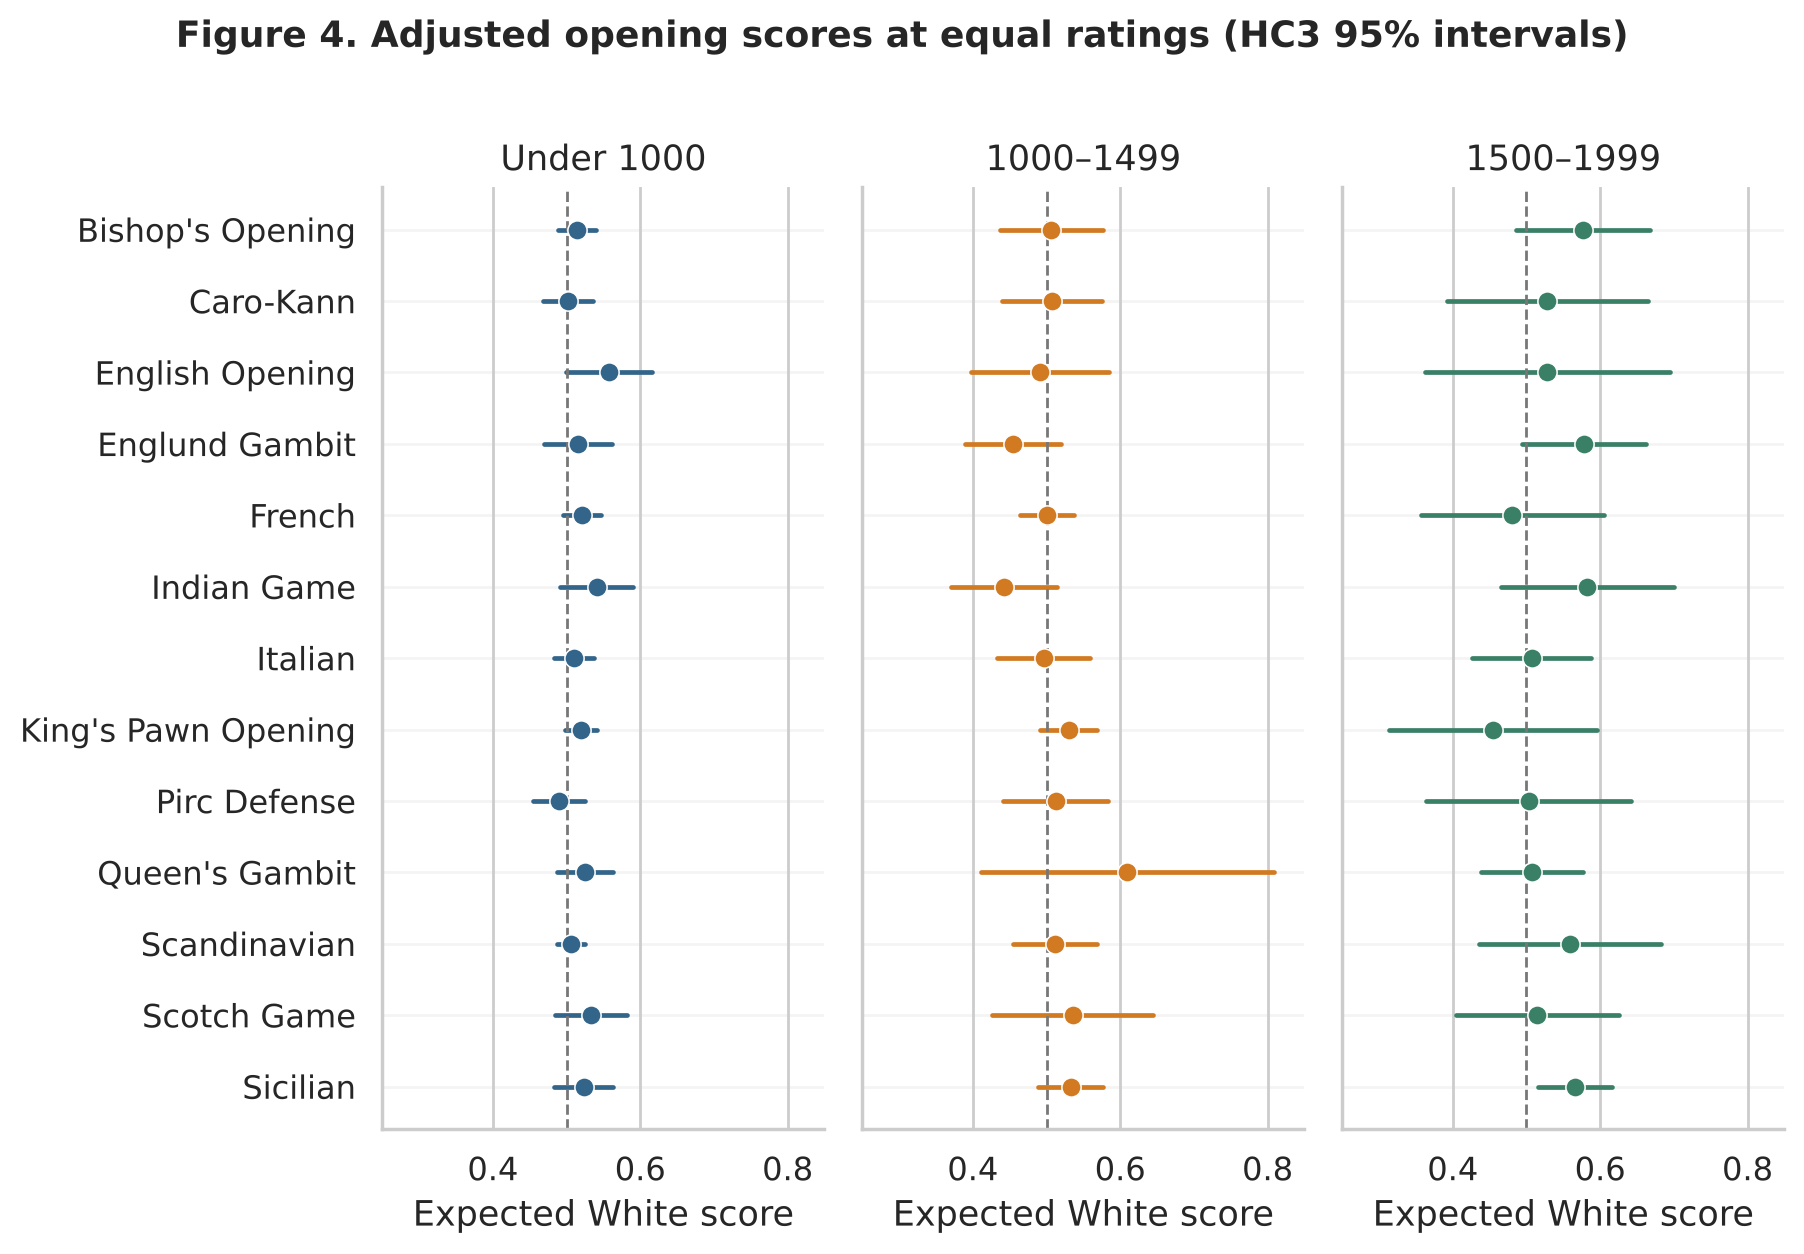

**Table 14. Highest estimated White score in each rating group (not proven best)**

,Rating group,Opening,Expected White score,Lower,Upper,Games
0,Under 1000,English Opening,0.5574,0.4988,0.6159,213
1,1000–1499,Queen's Gambit,0.6098,0.4108,0.8087,73
2,1500–1999,Indian Game,0.5827,0.4654,0.7000,57


Pairwise tests: 234 | unadjusted p < .05: 3 | significant after Holm correction: 0


In [10]:
weights = explore.time_control_group.value_counts(normalize=True)
vectors, mean_rows = {}, []
for group in groups:
    for opening in eligible:
        grid = pd.DataFrame({'opening_family':opening, 'rating_group':group, 'gap100':0, 'time_control_group':weights.index})
        matrix = np.asarray(build_design_matrices([design_info], grid)[0])
        vector = weights.to_numpy() @ matrix
        vectors[group, opening] = vector
        test = hc3.t_test(vector)
        low, high = np.asarray(test.conf_int()).ravel()
        mean_rows.append({'Rating group':group, 'Opening':opening, 'Expected White score':float(np.asarray(test.effect).item()),
                          'Lower':low, 'Upper':high, 'Games':int(all_counts.loc[opening, group])})
means = pd.DataFrame(mean_rows)
fig, axes = plt.subplots(1, 3, figsize=(9.2, 6.2), sharex=True, sharey=True)
for ax, group, color in zip(axes, groups, rating_colors):
    part = means[means['Rating group'] == group].set_index('Opening').loc[eligible].reset_index()
    sns.scatterplot(data=part, x='Expected White score', y='Opening', s=48, color=color, ax=ax, zorder=3)
    for j, row in part.iterrows():
        ax.plot([row.Lower, row.Upper], [j, j], color=color, linewidth=1.7)
    ax.axvline(.5, color='#777777', linestyle='--', linewidth=1)
    ax.set(title=group, xlabel='Expected White score', ylabel='', xlim=(.25, .85))
    ax.grid(axis='y', alpha=.2)
fig.suptitle('Figure 4. Adjusted opening scores at equal ratings (HC3 95% intervals)', fontsize=13, fontweight='bold', y=1.01)
sns.despine()
plt.tight_layout()
plt.savefig('figures/adjusted_opening_scores.png', dpi=180, bbox_inches='tight')
plt.show()
means.to_csv('exploratory_adjusted_scores.csv', index=False)
pair_rows = []
for group in groups:
    for first, second in combinations(eligible, 2):
        test = hc3.t_test(vectors[group, first] - vectors[group, second])
        pair_rows.append({'Rating group':group, 'First opening':first, 'Second opening':second,
                          'Difference':float(np.asarray(test.effect).item()), 'p':float(np.asarray(test.pvalue).item())})
pairs = pd.DataFrame(pair_rows)
pairs['Holm adjusted p'] = multipletests(pairs.p, method='holm')[1]
pairs.to_csv('exploratory_pairwise_tests.csv', index=False)
leaders = means.loc[means.groupby('Rating group')['Expected White score'].idxmax()].set_index('Rating group').reindex(groups).reset_index()
title('Table 14. Highest estimated White score in each rating group (not proven best)')
display(leaders[['Rating group','Opening','Expected White score','Lower','Upper','Games']])
print('Pairwise tests:', len(pairs), '| unadjusted p < .05:', int((pairs.p < .05).sum()),
      '| significant after Holm correction:', int((pairs['Holm adjusted p'] < .05).sum()))

English has the highest fitted White score under 1000 (about 0.557), Queen's Gambit at 1000-1499 (0.610), and Indian Game at 1500-1999 (0.583). These are the leaders in the point estimates, not proven best choices. In Phase 3 the 1500-1999 leader was Englund Gambit (0.578); merging the split `Indian` label added games to Indian Game and changed the leader, which itself shows how fragile these rankings are. The 1000-1499 leader's interval runs from 0.41 to 0.81, so it is consistent with Queen's Gambit being below average.

With 13 families in each of three groups, there are 234 within-group opening pairs to compare. Testing that many pairs makes chance findings easier to obtain: even with no real differences, about 12 of 234 tests would fall below 0.05 by luck. We therefore apply **Holm correction** (Holm, 1979), which adjusts the p-values across the entire set instead of letting us select whichever comparisons look significant. Only 3 pairs fall below 0.05 before correction, fewer than chance alone would produce, and none passes the corrected threshold.

The joint test gives the same answer under our main method: HC3 joint p = 0.804, so we find no clear evidence that opening differences change with rating. The account-level version, which counts each account once per cell, agrees (p = 0.724), as does the quadratic-gap version (p = 0.719). Restricting rating gaps to 400 points gives p = 0.047, just below 0.05. That is one of five versions we ran after Phase 2, without correction for trying several specifications, so we treat it as weak and unconfirmed rather than as a finding. The source-account clustered test gives p of about 2 × 10^-26; as explained above, with only five accounts in 1500-1999 it is not a reliable measure, and the account-level test that addresses the same repeated-player concern does not support it.

Across the checks we can rely on, the fitted scores suggest patterns worth investigating, but the results are not strong enough for a dependable opening ranking.

## Evaluation of significance

For the two original tests, we use the planned two-sided 0.05 threshold:

In [11]:
planned_rows = []
for label, model, term in [('1. Sicilian minus French', m1, 'sicilian'),
                           ("2. Change in the King's-minus-Queen's Pawn difference between groups", m2, 'kings_pawn:rating_1000_1499')]:
    low, high = model.conf_int().loc[term]
    planned_rows.append({'Planned test':label, 'Estimate':round(model.params[term], 3),
                         '95% confidence interval':f'{low:.3f} to {high:.3f}', 'p-value':p_text(model.pvalues[term]),
                         'Decision':'Fail to reject zero' if model.pvalues[term] >= .05 else 'Reject zero'})
planned = pd.DataFrame(planned_rows)
planned.to_csv('planned_test_results.csv', index=False)
title('Table 15. Decisions for the two preregistered tests (α = 0.05, two-sided)')
display(planned)

**Table 15. Decisions for the two preregistered tests (α = 0.05, two-sided)**

,Planned test,Estimate,95% confidence interval,p-value,Decision
0,1. Sicilian minus French,0.0120,-0.195 to 0.219,0.911,Fail to reject zero
1,2. Change in the King's-minus-Queen's Pawn difference between groups,-0.1310,-0.616 to 0.355,0.592,Fail to reject zero


**What these numbers mean.** For the Sicilian-French test, p = 0.911 means that if the two families truly gave White the same average score, a difference at least as large as ours would appear about 91% of the time just from which games happened to be sampled. Our estimate is entirely ordinary under "no difference." The interval from -0.195 to 0.219 shows why we cannot go further and say the openings are equal: the data are also consistent with a difference of about 0.2 points, roughly the gap between a 50% and a 70% score. For the pawn interaction, p = 0.592 and an interval of about ±0.5 tell the same story with even less precision, because the test uses only 63 games.

So we fail to reject both null hypotheses. We report these as two individual planned tests, without correction for a combined claim; correcting them would not make either significant.

**Do the checks change the decision?** No. Removing the influential game (p = 0.578), using all eligible games with time control (p = 0.531 and p = 0.343), and limiting rating gaps all lead to the same decision. The full-data intervals are much narrower, so the main thing they add is that any real difference in these two comparisons is probably small, within a few hundredths of a point.

**Why these findings matter.** A player or coach might expect the choice between these common openings to have a large effect on results at a given rating. Once opponent strength is accounted for, our data show no detectable effect, while the 100-point rating advantage is clearly associated with about 0.1 more points per game. In these games, being the stronger player matters much more than which of these openings was played.

**Exploratory tests.** The main HC3 joint test (p = 0.804), the account-level test (p = 0.724) and the 234 Holm-corrected pairwise tests (none significant) all find no clear evidence that opening differences change with rating. Only the restricted-gap version falls just under 0.05, and only the clustered version, which we flag as unstable, is strongly significant. We therefore do not present a rating-dependent opening effect as a finding.

## Conclusions

We asked whether opening performance changes with rating after accounting for opponent strength.

**The two planned comparisons find no clear difference.** The Sicilian-French estimate is close to zero (0.012, p = 0.911), and the pawn-opening interaction (-0.131, p = 0.592) is too uncertain to establish a change between the two groups. These conclusions do not depend on the one highly influential game: without it, the Sicilian-French estimate is 0.055 (p = 0.578). Using thousands more games and controlling for time control does not make either comparison significant, and it narrows the intervals enough to suggest any real difference is small.

**No opening shows a dependable rating-specific advantage.** Across 13 families, English, Queen's Gambit and Indian Game have the highest estimated White scores in the three groups. But no pairwise advantage survives Holm correction, and our main joint test (HC3, p = 0.804) and the account-level test that counts each player once (p = 0.724) find no clear evidence that opening differences change with rating. The one strongly significant result came from clustering on very few accounts, which we judge unreliable.

**Opponent strength matters more than these opening choices.** In every model, the rating gap is associated with White's score, while the opening differences we tested are small or undetectable.

We therefore cannot recommend a dependable best opening for each rating from this dataset. That does not show that openings never matter. It shows that our observed rankings are not strong enough to support the recommendation we originally hoped to investigate. A useful follow-up would sample a fixed number of accounts in each rating group, cap the games taken from each account, and test the same comparisons on a new period.

## Limitations

### Who the games represent

We selected accounts, then collected their games. More active accounts contribute more observations, and their opponents are not a separate random sample. The balanced 600-game sample does not estimate platform-wide percentages. The larger set is heavily concentrated under 1000.

Repeated players matter more than the total game count suggests. In the full 1500-1999 group, two source accounts supply 1,470 of 1,584 games. A pattern there could reflect those players' habits rather than a general opening advantage. HC3 still assumes independent games; the account-level check counts each account once but loses information about how many games stand behind each average; clustering has too few accounts in the higher groups. None of these methods fully resolves the problem.

### What the opening labels and models leave out

We group Chess.com's URL labels rather than reconstructing board positions. One family can contain different variations, and different move orders can reach similar positions. King's Pawn Opening is a particular lookup category, not every game beginning 1.e4. Sicilian and French also depend on Black's response. Every score in the report is measured from White's side.

We do not fully measure opening preparation, familiarity, playing style, rating uncertainty or account history. Controlling for recorded ratings and time control cannot remove those influences. Linear regression can also produce fitted scores outside 0-1, as one extreme 1,272-point game showed.

### Limits of our significance metrics

- **A large p-value is not evidence of no effect.** Our planned-sample intervals are wide enough to include differences of about 0.2 points; "fail to reject" means the data cannot tell, not that the openings are equal.
- **Our p-values depend on independence assumptions.** Conventional and HC3 uncertainty treat games as separate pieces of evidence. Because a few accounts supply many games, the true uncertainty is probably larger than reported, which would make our non-significant results even less conclusive.
- **Multiple specifications.** After Phase 2 we ran five versions of the joint test. One crossed 0.05 (p = 0.047). Trying several versions raises the chance that one crosses the threshold by luck, so a single p-value just under 0.05 among them is weak evidence.
- **Statistical significance is not practical importance.** With thousands of games, even a tiny difference could become significant. We therefore report estimates and intervals, not only p-values.
- **The 0.05 threshold is a convention.** A result at p = 0.047 and one at p = 0.06 carry similar evidence even though they fall on different sides of the line.

### Potential harms

- **Misleading study advice.** Readers could treat our point-estimate leaders (English, Queen's Gambit, Indian Game) as recommendations. Players could spend study time on an opening because of a ranking our data do not support. We label these as unproven throughout.
- **Unfair characterization of rating groups.** Descriptive differences between groups, such as different scores or openings under 1000, could be read as claims that lower-rated players "play the wrong openings." Our data cannot support claims about the ability or choices of any group.
- **Privacy.** Public usernames and game URLs can identify accounts. Public access is not anonymity or proof that players expected this research use. We report group patterns, avoid individual rankings, and do not name the accounts that dominate the higher groups.
- **Suspicion of individuals.** Unusual results, such as the 1,272-point win, could be misread as evidence of cheating or sandbagging. We treat them as statistical outliers only.

### Where the conclusions apply

These are July-September 2026 rated standard blitz games from accounts on Chess.com's recently active US list. Results may not carry to rapid, bullet, over-the-board chess, other platforms or other periods. There are too few games in most 2000+ opening cells for our broad comparison, so we do not offer a high-rating ranking.

## Response to Phase 3 feedback

**Our questions for reviewers, and how we resolved them**

| Phase 3 question | Reviewer answer | Resolution in Phase 4 |
|---|---|---|
| 1. Is it clear which tests were planned in Phase 2 and which were added afterward? | TA: "Yes, it's clear." | Kept the separation. Every later analysis is labeled exploratory or a sensitivity check. |
| 2. Given the few source accounts behind many higher-rated games, which uncertainty method is reasonable? | TA: use HC3 as the default; clustering is unreliable with five accounts in 1500-1999. Also try aggregating to one row per account. | HC3 is now the main method; clustering is reported only as a flagged unstable check, with the reason (Cameron & Miller, 2015). We added the account-level test, which agrees with HC3 (p = 0.724). |
| 3. Is leaving 2000+ out of the broad comparison preferable to retaining very sparse opening cells? | TA: leaving it out is the right call; state it as a data gap. | Kept 2000+ out of the broad comparison and state it as a gap in the coverage discussion and limitations. |
| 4. Does the report clearly distinguish a high estimated score from evidence of a better opening? | TA: "Yes, very clear." | Kept the distinction; the leaders table is now titled "not proven best." |

**Other TA and peer feedback**

| Feedback | Change made |
|---|---|
| TA: rerun Sicilian-French excluding the influential game (Cook's D about 15). | New subsection and Tables 8-9. The estimate moves from 0.012 to 0.055 (p = 0.578); the conclusion holds. |
| TA: test a fix for the HC3 vs clustered disagreement by aggregating to one row per account. | Account-level joint test added to Table 12 (p = 0.724). |
| Peer: explain jargon such as opening family and rating. | Added "Chess terms used in this report" to the introduction and definitions of interaction, Cook's distance, HC3 and clustering where they first appear. |
| Peer: answer more fully what processes influenced which data were observed. | Added "What shaped which games we observed." |
| Peer: add more real-world application to the preregistration statements. | Added a "Real-world context" paragraph to each statement. |
| Peer: add titles to tables and number the hypotheses in the results. | Every table and figure is now numbered and titled; results headings are numbered 1 and 2. |
| Peer: explain the numbers under the significance table. | Added "What these numbers mean" below Table 15. |
| Peer: make potential harms and limits of significance metrics explicit. | Added separate "Limits of our significance metrics" and "Potential harms" subsections. |
| Found while revising: 14 split opening labels and a one-game time control category. | Fixed in the cleaning notebook (149 games relabeled; 10 games regrouped). Planned results unchanged; the broader comparison is updated. |

## Acknowledgements and bibliography

We acknowledge Chess.com as the producer and public provider of the game records, the INFO 2950 TA for Phase 2 and Phase 3 feedback, and our Phase 3 peer reviewers (gqb2, il323, jw2769) for their comments. OpenAI Codex assisted with recovering files, drafting and revising prose and code, running checks, and preparing figures and the Phase 3 report. Claude (Anthropic) assisted with the Phase 4 revisions, including the new sensitivity checks, the cleaning fixes, and revised prose. We reviewed and are responsible for all content.

- Cameron, A. C., & Miller, D. L. (2015). A practitioner's guide to cluster-robust inference. *Journal of Human Resources, 50*(2), 317-372. https://doi.org/10.3368/jhr.50.2.317
- Chess.com. (n.d.-a). *Published Data API*. https://www.chess.com/news/view/published-data-api
- Chess.com. (n.d.-b). *How do ratings work on Chess.com?* https://support.chess.com/en/articles/8566476-how-do-ratings-work-on-chess-com
- De Marzo, G., & Servedio, V. D. P. (2023). Quantifying the complexity and similarity of chess openings using online chess community data. *Scientific Reports, 13*, 5327. https://doi.org/10.1038/s41598-023-31658-w
- Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W., Wallach, H., Daumé III, H., & Crawford, K. (2018). *Datasheets for datasets*. arXiv. https://arxiv.org/abs/1803.09010
- Goetz, T., & Grabowski, N. (2026). *INFO 2950 chess project: archived data, cleaning notebook and project materials*. https://github.com/Toyman123/info2950-project
- Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*(2), 65-70.
- Waskom, M. L. (2021). seaborn: statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021
- statsmodels developers. (n.d.). *statsmodels documentation: regression, covariance estimation and multiple testing*. https://www.statsmodels.org/stable/
- DuckDB Foundation. (n.d.). *DuckDB documentation*. https://duckdb.org/docs/
- pandas development team. (n.d.). *pandas documentation*. https://pandas.pydata.org/docs/
- Matplotlib development team. (n.d.). *Matplotlib documentation*. https://matplotlib.org/stable/
- NumPy developers. (n.d.). *NumPy documentation*. https://numpy.org/doc/
- Patsy developers. (n.d.). *Patsy documentation*. https://patsy.readthedocs.io/

We used pandas for tables, DuckDB SQL for filtering and summaries, Seaborn and Matplotlib for figures, NumPy and Patsy for model inputs, and statsmodels for estimation and tests. No new games were collected for Phase 4.